---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

---

## Group 23: NoName

- Kloce Paul William Saragih (13524040)
- Yayat Nurhidayat (13223071)
- Cristopher Justin Kurniawan (13323032)
- Kholida Rezki Khoiriah (13222071)
- Buege Mahara Putra (13523037)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

A hotel wants to know which bookings will be canceled so it can plan rooms and staff ahead of time. This notebook predicts the is_canceled label of a booking from its attributes such as lead time, nightly rate, booking channel, and the number of special requests.

## Aim

- Implement KNN, Decision Tree Learning (C4.5), Logistic Regression (none, L1, L2, Elastic Net), SVM (linear, polynomial, Gaussian), and Naive Bayes from scratch.
- Compare every model with its scikit-learn counterpart.
- Save and load the models, then submit best model to Kaggle.

## Metric

Main metric is F1 on the canceled class (is_canceled = 1).

## Dataset

train.csv has 27,373 bookings with 17 attributes and the target, and test.csv has 6,844 bookings without the target. Three attributes are categorical (meal_package, room_category, booking_channel) and the rest are numeric.

## Approach

1. Split train.csv into 80% training and 20% validation with stratification.
2. Clean and transform the data with statistics from the training split only, into three formats: dense (scaled, one-hot), tree (ordinal codes), and discrete (for Naive Bayes).
3. Train every model on the training split and report the validation metrics.
4. Compare with scikit-learn, save and reload every model, and fit the best model on the full training set for the submission.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import random
import re
import sys
from collections.abc import Callable
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from sklearn.feature_selection import mutual_info_classif

In [3]:
sys.path.insert(0, str(Path('src').resolve()))

from model import BaseModel, KNN, C45DecisionTree, LogisticRegression, SVM, NaiveBayes, Preprocessor, metrics

## Settings

Paths and shared constants are kept in this class.

In [4]:
class Settings:
    SEED       = 67
    TARGET     = 'is_canceled'
    VAL_SIZE   = 0.2
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')
    MODEL_DIR  = Path('models')
    ID          = 'id'
    CATEGORICAL = ['meal_package', 'room_category', 'booking_channel']

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [5]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [6]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [7]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[c]) else 'categorical' for c in df]

    return pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'kind': kinds,
        'unique': df.nunique(),
        'missing': df.isna().sum(),
        'missing %': (df.isna().mean() * 100).round(1),
        'example': df.iloc[0],
    })

types(train_df)

,dtype,kind,unique,missing,missing %,example
id,str,categorical,27373,0,0.0,57152f82
num_adults,float64,numeric,5,809,3.0,2.0
num_children,float64,numeric,6,3035,11.1,NaN
weekend_nights,int64,numeric,8,0,0.0,1
weekday_nights,int64,numeric,18,0,0.0,2
meal_package,str,categorical,4,1760,6.4,Breakfast
needs_parking,float64,numeric,2,1082,4.0,0.0
room_category,str,categorical,7,1002,3.7,Type B
days_before_arrival,float64,numeric,407,1123,4.1,88.0
arrival_year,int64,numeric,2,0,0.0,2024


In [8]:
NUMERIC = [c for c in train_df.select_dtypes('number').columns if c != CFG.TARGET]

train_df[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,85.38,85.97,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2023.82,0.38,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.40,3.07,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,15.54,8.77,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,0.03,0.16,0.0,0.0,0.0,0.0,1.0


In [9]:
for column in CFG.CATEGORICAL:
    print(column, train_df[column].value_counts(dropna=False).to_dict())

meal_package {'Breakfast': 19654, 'Room Only': 3713, 'Half Board': 2242, nan: 1760, 'Full Board': 4}
room_category {'Type B': 20447, 'Type G': 4396, nan: 1002, 'Type A': 699, 'Type D': 514, 'Type C': 189, 'Type F': 119, 'Type E': 7}
booking_channel {'Online Travel Agent': 17511, 'Offline Agent': 7960, 'Corporate': 1513, 'Complimentary': 301, 'Airline': 88}


In [10]:
print(train_df['num_children'].value_counts(dropna=False).sort_index())
train_df[train_df['num_children'] >= 9][['num_adults', 'num_children', 'room_category', 'nightly_rate_idr', CFG.TARGET]]

num_children
0.0     22318
1.0      1221
2.0       780
3.0        16
9.0         2
10.0        1
NaN      3035
Name: count, dtype: int64


,num_adults,num_children,room_category,nightly_rate_idr,is_canceled
9094,2.0,10.0,Type G,1413000.0,0
9214,2.0,9.0,Type D,1231000.0,1
24750,1.0,9.0,Type B,1578000.0,0


There are 27373 number of rows 

The highest missing ratio is num_children and special_requests with value 11.1% and 9.1%
days_before_arrival, prior_completed_bookings, and nightly_rate_idr have long right tails mean > median.

Full Board, Type E, and Airline category are very rare

## Explore Data

This part covers distributions and relationships between attributes.

In [11]:
CONTINUOUS = ['days_before_arrival', 'nightly_rate_idr', 'arrival_day']

def as_list(columns):
    return [columns] if isinstance(columns, str) else list(columns)

def make_axes(count, ncols=3):
    nrows = -(-count // ncols)
    figure, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)

    for axis in axes.flat[count:]:
        axis.axis('off')

    return axes.flat[:count]

def histogram(df, columns, by=None, bins=30, normalize=False):
    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        values = df[column].dropna()

        if values.nunique() <= 20:
            edges = np.arange(values.min() - 0.5, values.max() + 1.5)
        else:
            edges = np.histogram_bin_edges(values, bins=bins)

        if by is None:
            axis.hist(values, bins=edges)
        else:
            for label, group in df.groupby(by):
                axis.hist(group[column].dropna(), bins=edges, alpha=0.5, density=normalize, label=str(label))
            axis.legend(title=by)

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

def density(df, columns, by=CFG.TARGET, upper=0.99):
    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        limit = df[column].quantile(upper)

        for label, group in df.groupby(by):
            values = group[column].dropna()
            values[values <= limit].plot.kde(ax=axis, label=str(label))

        axis.set_xlim(df[column].min(), limit)
        axis.set_title(column)
        axis.legend(title=by)

    plt.tight_layout()
    plt.show()

def boxplot(df, columns):
    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        axis.boxplot(df[column].dropna())
        axis.set_xticks([])
        axis.set_title(column)

    plt.tight_layout()
    plt.show()

def target_rate(df, columns):
    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        df.groupby(column)[CFG.TARGET].mean().plot.bar(ax=axis)
        axis.axhline(df[CFG.TARGET].mean(), color='gray', linestyle='--', linewidth=1)
        axis.set_title(column)
        axis.set_ylabel(f'rate {CFG.TARGET}')

    plt.tight_layout()
    plt.show()

def correlation(df):
    values = df[NUMERIC].corrwith(df[CFG.TARGET])

    return values.reindex(values.abs().sort_values(ascending=False).index)

def correlation_bar(df):
    correlation(df).plot.barh(figsize=(6, 5))
    plt.axvline(0, color='gray', linewidth=1)
    plt.gca().invert_yaxis()
    plt.title(f'Correlation with {CFG.TARGET}')
    plt.tight_layout()
    plt.show()

def correlation_heatmap(df):
    corr = df[NUMERIC + [CFG.TARGET]].corr()

    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)

    for (i, j), value in np.ndenumerate(corr.to_numpy()):
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=7)

    fig.colorbar(image)
    ax.set_title('Correlation between numeric features')
    plt.tight_layout()
    plt.show()

def year_month(df):
    counts = pd.crosstab(df['arrival_month'], df['arrival_year'])
    rates = df.pivot_table(index='arrival_month', columns='arrival_year', values=CFG.TARGET, aggfunc='mean')

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    counts.plot.bar(ax=axes[0])
    axes[0].set_title('Bookings per arrival month')
    axes[0].set_xlabel('arrival_month')
    axes[0].set_ylabel('bookings')
    axes[0].tick_params(axis='x', rotation=0)

    rates.plot(ax=axes[1], marker='o')
    axes[1].set_title(f'{CFG.TARGET} rate per arrival month')
    axes[1].set_xlabel('arrival_month')
    axes[1].set_ylabel(f'rate {CFG.TARGET}')
    axes[1].set_xticks(range(1, 13))

    plt.tight_layout()
    plt.show()

In [12]:
train_df[CFG.TARGET].value_counts(normalize=True).round(3)

is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64

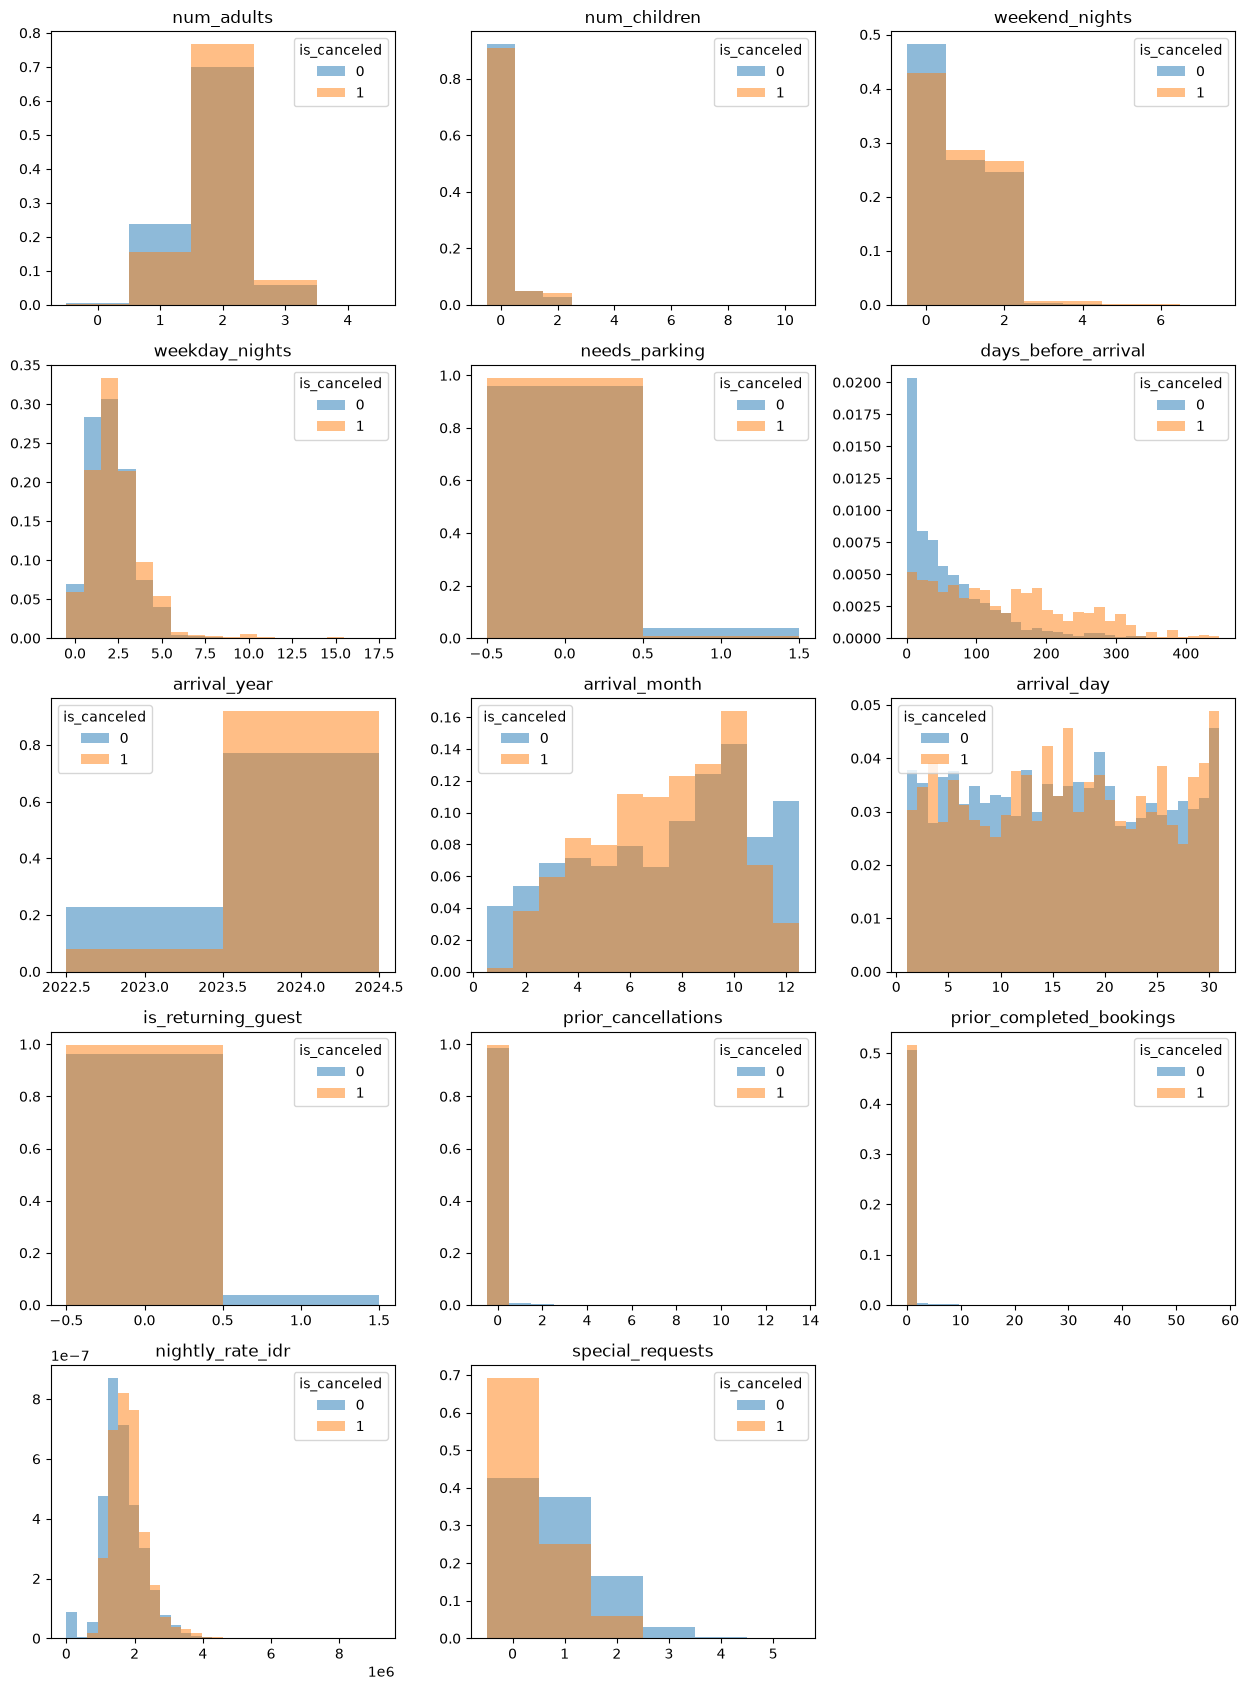

In [13]:
histogram(train_df, NUMERIC, by=CFG.TARGET, normalize=True)

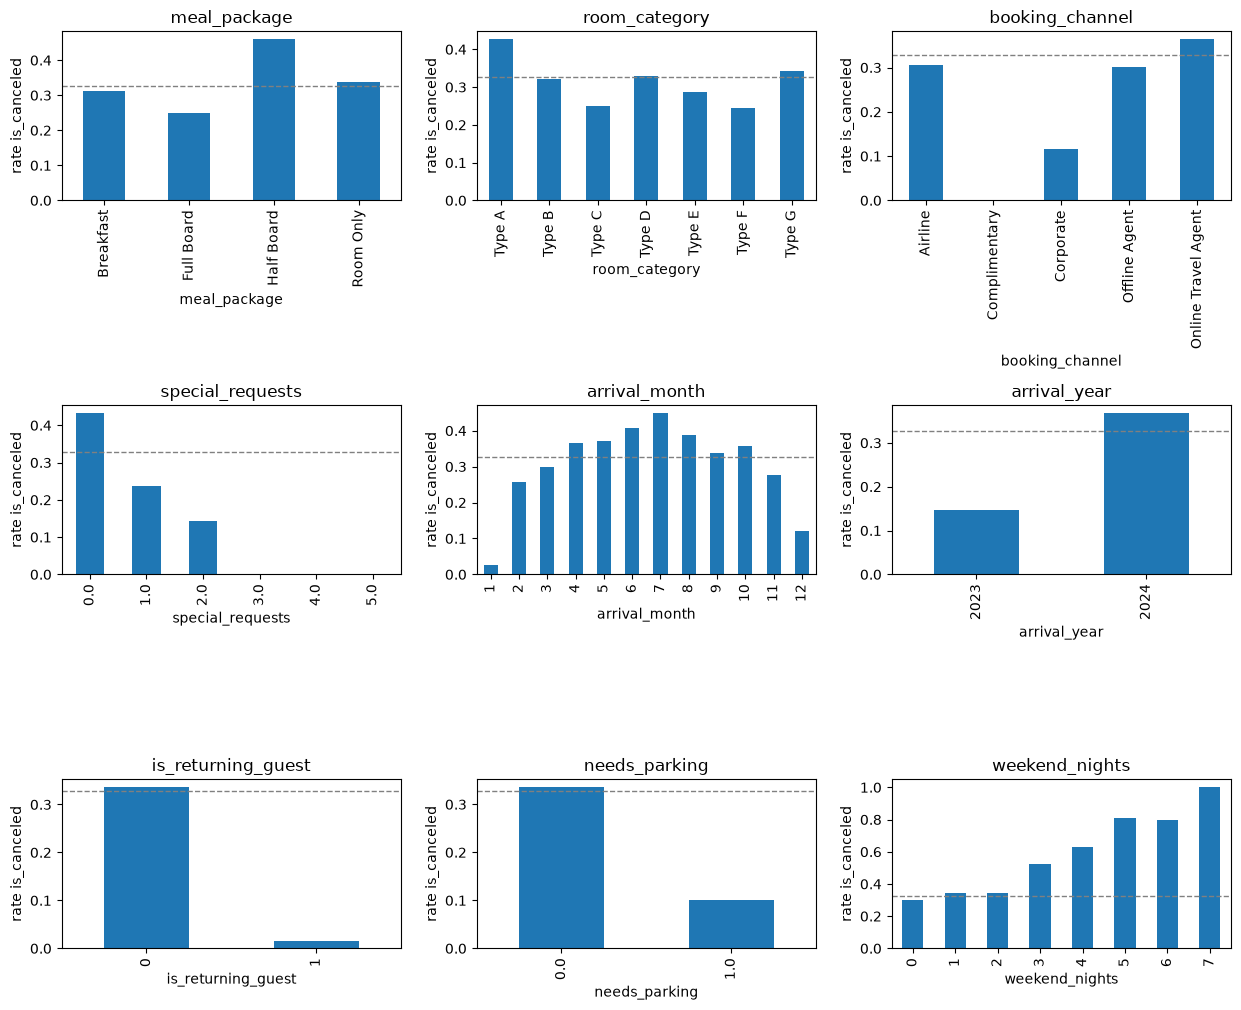

In [14]:
target_rate(train_df, CFG.CATEGORICAL + ['special_requests', 'arrival_month', 'arrival_year',
                                          'is_returning_guest', 'needs_parking', 'weekend_nights'])

Data with complimentary in booking category never cancel, simply because is complimentary?
As special request goes up, cancellation rate goes down, i think its make sense cause people with higher special request will hesitate to cancel more

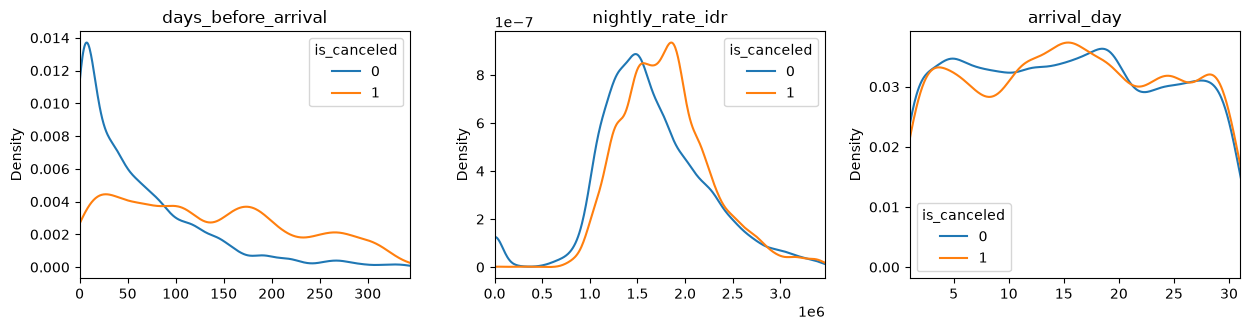

In [15]:
density(train_df, CONTINUOUS)

In [16]:
correlation(train_df).round(3)

days_before_arrival         0.440
special_requests           -0.258
arrival_year                0.180
nightly_rate_idr            0.134
is_returning_guest         -0.107
weekday_nights              0.097
num_adults                  0.088
needs_parking              -0.086
weekend_nights              0.061
prior_completed_bookings   -0.059
prior_cancellations        -0.035
num_children                0.031
arrival_day                 0.020
arrival_month              -0.016
dtype: float64

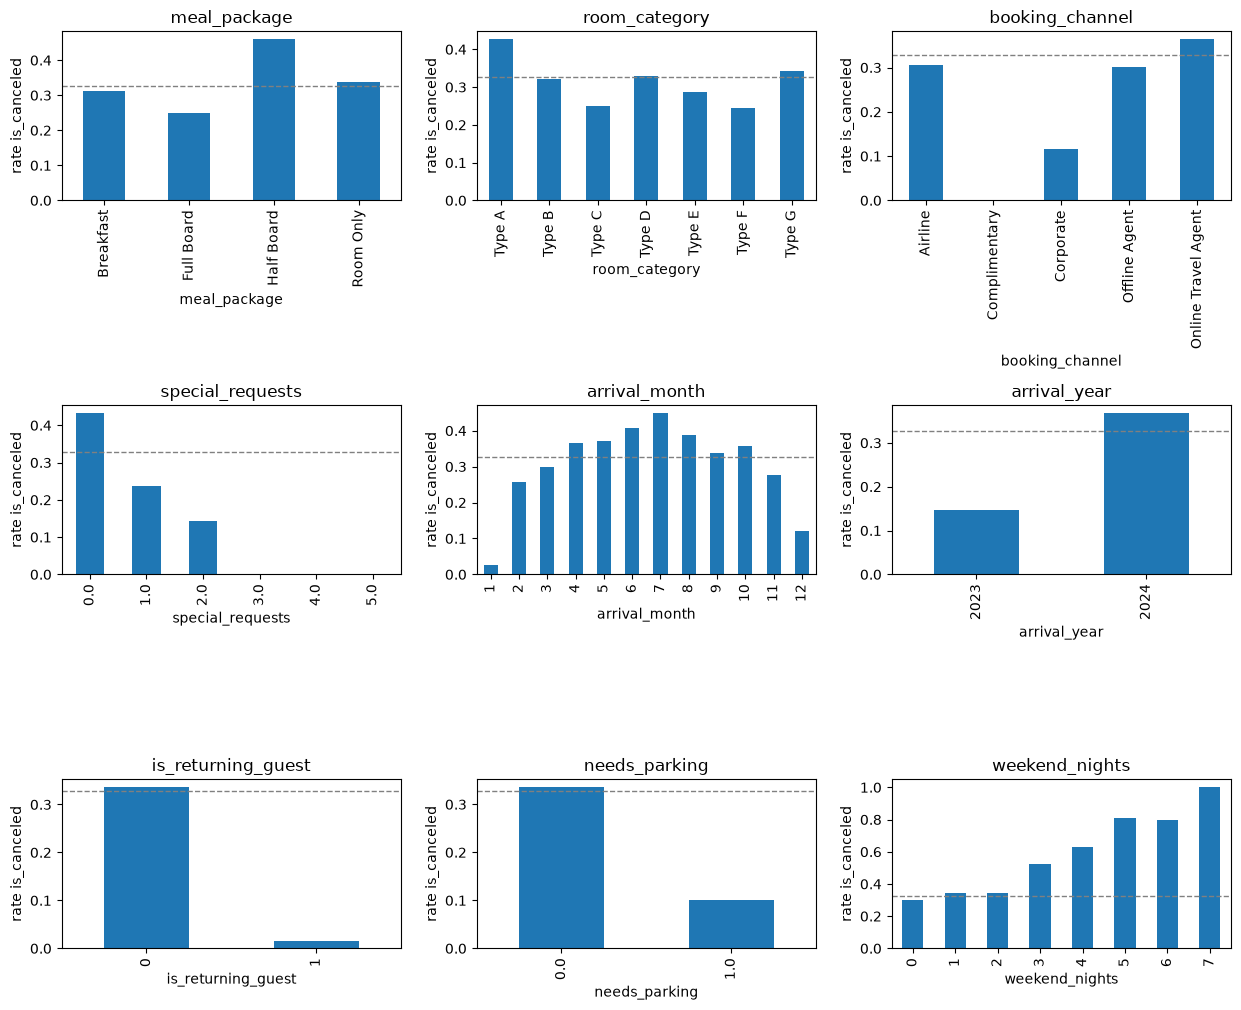

In [17]:
target_rate(train_df, CFG.CATEGORICAL + ['special_requests', 'arrival_month', 'arrival_year',
                                          'is_returning_guest', 'needs_parking', 'weekend_nights'])

In [18]:
lead_time_bins = pd.cut(train_df['days_before_arrival'], [-1, 7, 30, 90, 180, 270, 500])
rate_bins = pd.qcut(train_df['nightly_rate_idr'], 8)

pd.concat({
    'days_before_arrival': train_df.groupby(lead_time_bins, observed=True)[CFG.TARGET].agg(['size', 'mean']),
    'nightly_rate_idr': train_df.groupby(rate_bins, observed=True)[CFG.TARGET].agg(['size', 'mean']),
}).round(3)

size   mean
days_before_arrival (-1.0, 7.0]             4116  0.096
                    (7.0, 30.0]             4868  0.183
                    (30.0, 90.0]            7847  0.253
                    (90.0, 180.0]           5573  0.451
                    (180.0, 270.0]          2484  0.702
                    (270.0, 500.0]          1362  0.798
nightly_rate_idr    (-0.001, 1168000.0]     3178  0.169
                    (1168000.0, 1338000.0]  3172  0.269
                    (1338000.0, 1496000.0]  3171  0.274
                    (1496000.0, 1644000.0]  3152  0.327
                    (1644000.0, 1819000.0]  3164  0.381
                    (1819000.0, 2019000.0]  3168  0.473
                    (2019000.0, 2336000.0]  3165  0.389
                    (2336000.0, 9165000.0]  3165  0.349

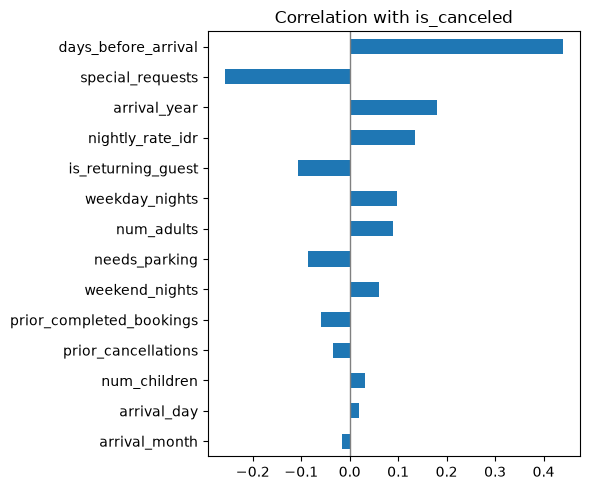

In [19]:
correlation_bar(train_df)

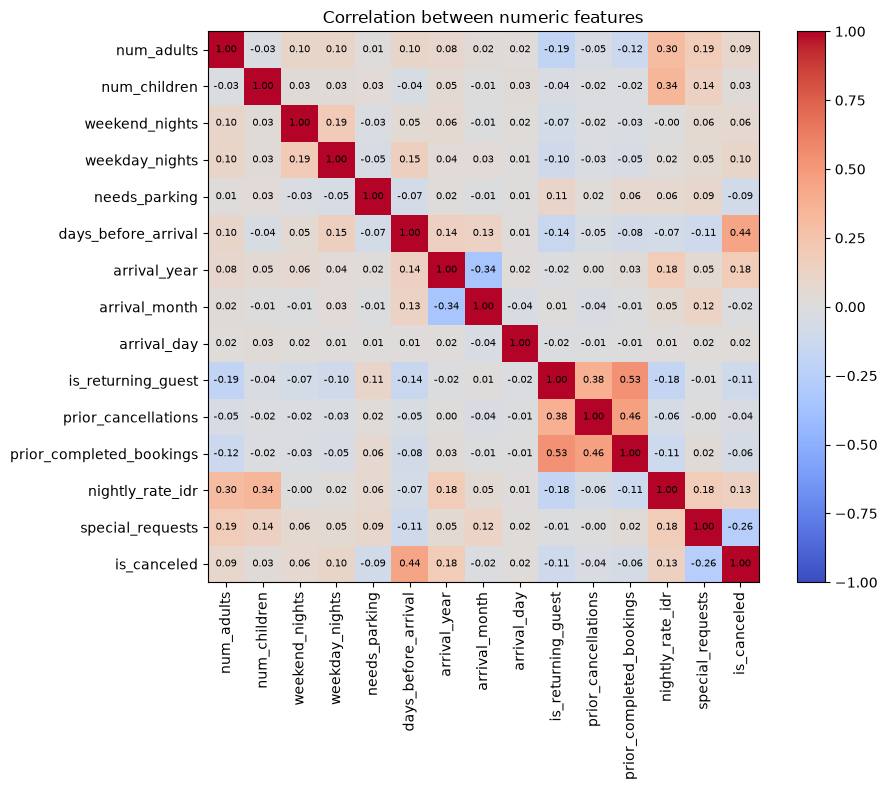

In [20]:
correlation_heatmap(train_df)

In [21]:
pd.crosstab(train_df['arrival_year'], train_df['arrival_month'])

arrival_month,1,2,3,4,5,6,7,8,9,10,11,12
arrival_year,,,,,,,,,,,,
2023,0,0,0,0,0,0,274,776,1241,1451,463,719
2024,777,1336,1786,2066,1935,2462,1924,2067,2217,2651,1696,1532


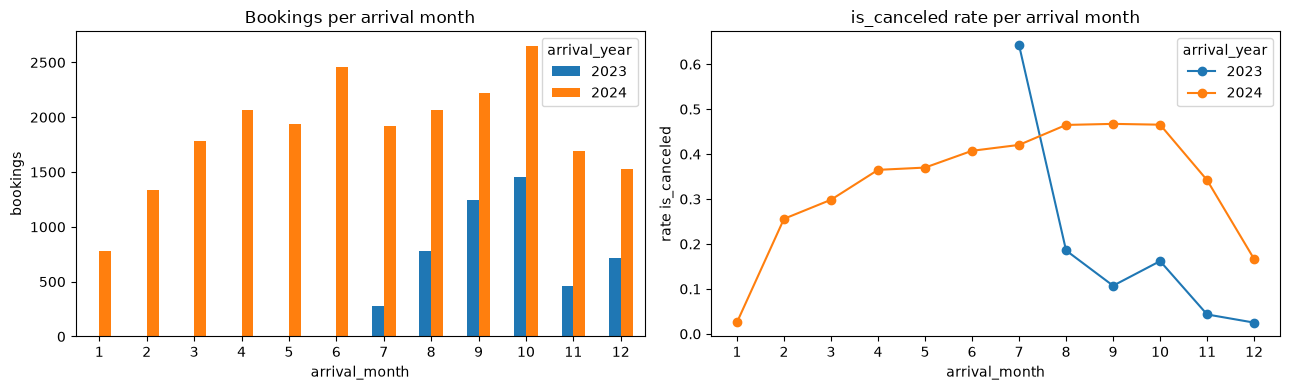

In [22]:
year_month(train_df)

Class distribution is 1/3 canceld, 2/3 not canceled'

Days before arrival has highest correlation to is_canceled



## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [23]:
def missing(train, test):
    features = test.columns.drop(CFG.ID)
    table = pd.DataFrame({
        'train': train[features].isna().mean() * 100,
        'test': test[features].isna().mean() * 100,
    }).round(2)

    return table[table.max(axis=1) > 0]

print('rows with at least one missing value:', round(train_df.isna().any(axis=1).mean() * 100, 1), '%')
missing(train_df, test_df)

rows with at least one missing value: 39.2 %


,train,test
num_adults,2.96,2.63
num_children,11.09,10.91
meal_package,6.43,6.46
needs_parking,3.95,3.61
room_category,3.66,3.54
days_before_arrival,4.10,4.24
nightly_rate_idr,7.45,7.89
special_requests,9.13,8.66


8 columns have empty cells, mostly between 3% and 11%, and the rates are almost the same in train and test. together they touch 39.2% of all rows, so dropping those rows would throw away too much data. might be better to fill the gaps instead.

In [24]:
features = list(train_df.columns.drop([CFG.ID, CFG.TARGET]))

pd.Series({
    'exact duplicates in train': train_df.drop(columns=CFG.ID).duplicated().sum(),
    'same features, different label': train_df.groupby(features, dropna=False)[CFG.TARGET].nunique().gt(1).sum(),
    'duplicates in test': test_df.drop(columns=CFG.ID).duplicated().sum(),
})

exact duplicates in train         64
same features, different label     2
duplicates in test                 3
dtype: int64

There are 64 rows in train that are duplicates

In [25]:
rate = train_df['nightly_rate_idr']
complimentary = train_df['booking_channel'] == 'Complimentary'

checks = {
    'num_children >= 9': train_df['num_children'] >= 9,
    'zero nights': train_df[['weekend_nights', 'weekday_nights']].sum(axis=1) == 0,
    'zero adults': train_df['num_adults'] == 0,
    'zero rate, complimentary': (rate == 0) & complimentary,
    'zero rate, other channel': (rate == 0) & ~complimentary,
    'rate between 0 and 100k': (rate > 0) & (rate < 100_000),
}

pd.DataFrame({
    name: {'rows': mask.sum(), 'cancel rate': train_df.loc[mask, CFG.TARGET].mean()}
    for name, mask in checks.items()
}).T.round(3)

,rows,cancel rate
num_children >= 9,3.0,0.333
zero nights,64.0,0.031
zero adults,106.0,0.302
"zero rate, complimentary",267.0,0.000
"zero rate, other channel",146.0,0.021
rate between 0 and 100k,28.0,0.000


zero night bookings are probably only used for day and almost never cancel, zero adult bookings nearly all include children, and zero rate bookings are mostly complimentary stays. the only real errors are the 3 bookings with 9 or 10 children in a single room, might be better to treat it as wrong input.

In [26]:
{c: sorted(set(test_df[c].dropna()) - set(train_df[c].dropna())) for c in CFG.CATEGORICAL}

{'meal_package': [], 'room_category': [], 'booking_channel': []}

every category in test also appears in train, so the encoder won't meet anything new. we still set it up to handle unseen values, just in case.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [27]:
train_set, val_set = train_test_split(
    train_df, test_size=CFG.VAL_SIZE, stratify=train_df[CFG.TARGET], random_state=CFG.SEED
)
print(train_set.shape, val_set.shape)

(21898, 19) (5475, 19)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [28]:
FEATURES = [c for c in train_df.columns if c not in (CFG.ID, CFG.TARGET)]
NUMERIC_FEATURES = [c for c in FEATURES if c not in CFG.CATEGORICAL]

X_train, y_train = train_set[FEATURES].copy(), train_set[CFG.TARGET].copy()
X_val, y_val = val_set[FEATURES].copy(), val_set[CFG.TARGET].copy()
X_test = test_df[FEATURES].copy()

pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

X_train    21898
X_val       5475
X_test      6844
dtype: int64

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Duplicates

This part covers repeated records.

In [29]:
def drop_duplicates(X, y):
    keep = ~pd.concat([X, y], axis=1).duplicated()
    return X[keep].copy(), y[keep].copy()

before = len(X_train)
X_train, y_train = drop_duplicates(X_train, y_train)
print('duplicates removed from the training split:', before - len(X_train))

duplicates removed from the training split: 43


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [30]:
def fix_data_errors(frames):
    for frame in frames:
        frame.loc[frame['num_children'] >= 9, 'num_children'] = np.nan

frames = [X_train, X_val, X_test]

print('num_children >= 9 in X_train:', (X_train['num_children'] >= 9).sum())
fix_data_errors(frames)
print('largest num_children after fix:', X_train['num_children'].max())

num_children >= 9 in X_train: 2
largest num_children after fix: 3.0


### Missing Values

This part covers missing values, if any.

In [31]:
def impute(fit, frames, columns, strategy='median'):
    columns = as_list(columns)
    imputer = SimpleImputer(strategy=strategy).fit(fit[columns])

    for frame in frames:
        frame[columns] = imputer.transform(frame[columns])

    return imputer

frames = [X_train, X_val, X_test]

numeric_imputer = impute(X_train, frames, NUMERIC_FEATURES, 'median')
categorical_imputer = impute(X_train, frames, CFG.CATEGORICAL, 'most_frequent')

pd.Series(dict(zip(NUMERIC_FEATURES + CFG.CATEGORICAL,
                   list(numeric_imputer.statistics_) + list(categorical_imputer.statistics_))))

num_adults                                  2.0
num_children                                0.0
weekend_nights                              1.0
weekday_nights                              2.0
needs_parking                               0.0
days_before_arrival                        58.0
arrival_year                             2024.0
arrival_month                               8.0
arrival_day                                16.0
is_returning_guest                          0.0
prior_cancellations                         0.0
prior_completed_bookings                    0.0
nightly_rate_idr                      1641000.0
special_requests                            0.0
meal_package                          Breakfast
room_category                            Type B
booking_channel             Online Travel Agent
dtype: object

### Outliers

This part covers values far from the rest of the data.

In [32]:
def cap_outliers(fit, frames, columns, factor=1.5):
    columns = as_list(columns)
    q1, q3 = fit[columns].quantile(0.25), fit[columns].quantile(0.75)
    lower, upper = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)

    for frame in frames:
        frame[columns] = frame[columns].clip(lower, upper, axis=1)

    return lower, upper

CAP_COLUMNS = ['nightly_rate_idr', 'days_before_arrival']
lower, upper = cap_outliers(X_train, frames, CAP_COLUMNS)

pd.DataFrame({'lower': lower, 'upper': upper, 'rows capped': (X_train[CAP_COLUMNS] == upper).sum()})

,lower,upper,rows capped
nightly_rate_idr,439500.0,2907500.0,708
days_before_arrival,-136.5,275.5,942


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

No attribute is derived. The dataset has only 17 raw attributes, and the tree and Naive Bayes models already capture interactions on their own. Keeping the raw attributes also keeps the preprocessing for all models identical.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [33]:
X_train_tree, X_val_tree, X_test_tree = X_train.copy(), X_val.copy(), X_test.copy()

def scale(fit, frames, columns, kind='standard'):
    columns = as_list(columns)
    scalers = {'standard': StandardScaler, 'minmax': MinMaxScaler, 'robust': RobustScaler}
    scaler = scalers[kind]().fit(fit[columns])

    for frame in frames:
        frame[columns] = scaler.transform(frame[columns])

frames = [X_train, X_val, X_test]
scale(X_train, frames, NUMERIC_FEATURES)
X_train[NUMERIC_FEATURES].describe().T[['mean', 'std']].round(2)

,mean,std
num_adults,-0.0,1.0
num_children,-0.0,1.0
weekend_nights,0.0,1.0
weekday_nights,0.0,1.0
needs_parking,-0.0,1.0
days_before_arrival,0.0,1.0
arrival_year,-0.0,1.0
arrival_month,-0.0,1.0
arrival_day,-0.0,1.0
is_returning_guest,0.0,1.0


The columns have very different number scales like nightly rate is in the millions, lead time is in the hundreds, and most other columns are between 0 and 3. Without scaling, the rate would dominate the distance in KNN and the training of logistic regression and SVM, just because its numbers are bigger. Standardizing puts every numeric column on the same scale with mean 0 and standard deviation 1.

### Encoding

This part covers the numeric representation of categorical attributes.

In [34]:
MEAL_ORDER = ['Room Only', 'Breakfast', 'Half Board', 'Full Board']

def encode(fit, frames, columns, kind='onehot', order=None, min_frequency=20):
    columns = as_list(columns)

    if kind == 'onehot':
        encoder = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=min_frequency, sparse_output=False)
    else:
        categories = [order] * len(columns) if order else 'auto'
        encoder = OrdinalEncoder(categories=categories, handle_unknown='use_encoded_value',
                                 unknown_value=-1, min_frequency=min_frequency)

    encoder.fit(fit[columns])
    names = list(encoder.get_feature_names_out(columns))

    for frame in frames:
        encoded = encoder.transform(frame[columns])
        for column in columns:
            del frame[column]
        frame[names] = encoded

frames = [X_train, X_val, X_test]
encode(X_train, frames, CFG.CATEGORICAL, 'onehot')

tree_frames = [X_train_tree, X_val_tree, X_test_tree]
encode(X_train_tree, tree_frames, 'meal_package', 'ordinal', order=MEAL_ORDER)
encode(X_train_tree, tree_frames, ['room_category', 'booking_channel'], 'ordinal')

print('dense:', X_train.shape, ' tree:', X_train_tree.shape)

dense: (21855, 30)  tree: (21855, 17)


Encoding change categorical feature into numeric representation so the model can work with the data. Because room type and channel have no natural order, they become one-hot columns (one 0/1 column per category). But Meals do have an order, from Room Only to Full Board, so the tree models get them as ordered codes. Full Board and Type E have fewer than 10 bookings each, too few to learn from, so they are grouped with other rare categories.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

30 columns, 15 components keep 95% of the variance


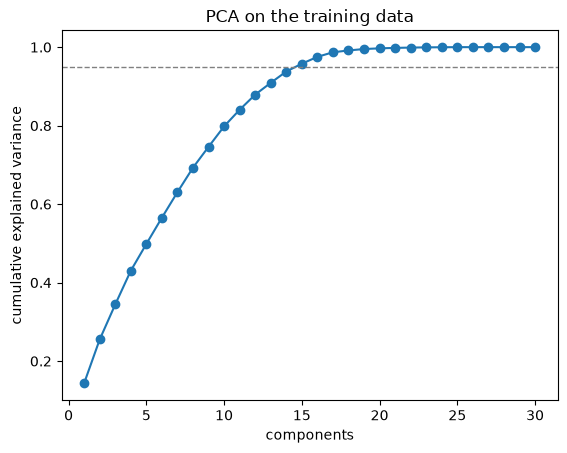

In [35]:
pca = PCA(random_state=CFG.SEED).fit(X_train)
cumulative = np.cumsum(pca.explained_variance_ratio_)

print(X_train.shape[1], 'columns,', np.argmax(cumulative >= 0.95) + 1, 'components keep 95% of the variance')

plt.plot(range(1, len(cumulative) + 1), cumulative, marker='o')
plt.axhline(0.95, color='gray', linestyle='--', linewidth=1)
plt.xlabel('components')
plt.ylabel('cumulative explained variance')
plt.title('PCA on the training data')
plt.show()

We dont use the dimensionality reduction because 30 features are already small in this case

## Class Balance

This part covers the proportion of each class in the training data.

In [36]:
pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'val': y_val.value_counts(normalize=True),
}).round(3)

,train,val
is_canceled,,
0,0.673,0.672
1,0.327,0.328


Only about 1 in 3 bookings is canceled both in train and val. So udge the models by F1 on the canceled class.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [37]:
categorical_idx = [list(X_train_tree.columns).index(c) for c in CFG.CATEGORICAL]

nb_prep = Preprocessor().fit(train_set)
Xn_train, _ = nb_prep.transform_nb(train_set.loc[X_train.index])
Xn_val, _ = nb_prep.transform_nb(val_set)
nb_idx = list(range(Xn_train.shape[1]))

data = {
    'dense': (X_train.to_numpy(dtype=float), y_train.to_numpy(), X_val.to_numpy(dtype=float), y_val.to_numpy()),
    'tree': (X_train_tree.to_numpy(dtype=float), y_train.to_numpy(), X_val_tree.to_numpy(dtype=float), y_val.to_numpy()),
    'nb': (Xn_train, y_train.to_numpy(), Xn_val, y_val.to_numpy()),
}

for variant, (Xt, yt, Xv, yv) in data.items():
    print(variant, Xt.shape, Xv.shape, Xt.dtype)
print('tree categorical columns:', categorical_idx)

dense (21855, 30) (5475, 30) float64
tree (21855, 17) (5475, 17) float64
nb (21855, 17) (5475, 17) float64
tree categorical columns: [14, 15, 16]


The Naive Bayes format has the same 17 columns, but every one of them is a discrete code. Counts are capped, skewed numeric columns are cut into quantile bins, and all of them are modeled as categories with Laplace smoothing.

## Feature Selection

Selection keeps the attributes that carry information about the target. Each attribute is scored by its mutual information with `is_canceled` on the training split. Then Naive Bayes is retrained without one attribute at a time, to see how much F1 on the validation split changes.

In [38]:
nb_names = nb_prep.nb_feature_names
Xt, yt, Xv, yv = data['nb']

mi = mutual_info_classif(Xt, yt, discrete_features=True, random_state=CFG.SEED)
base_f1 = metrics.f1_score(yv, NaiveBayes(categorical=nb_idx).fit(Xt, yt).predict(Xv))

rows = []
for j, name in enumerate(nb_names):
    keep = [c for c in nb_idx if c != j]
    model = NaiveBayes(categorical=list(range(len(keep)))).fit(Xt[:, keep], yt)
    rows.append({'feature': name, 'mutual_info': mi[j], 'f1_without': metrics.f1_score(yv, model.predict(Xv[:, keep]))})

feature_scores = pd.DataFrame(rows).set_index('feature')
feature_scores['f1_change'] = feature_scores['f1_without'] - base_f1
print('Naive Bayes F1 with all features:', round(base_f1, 4))
feature_scores.sort_values('mutual_info', ascending=False).round(4)

Naive Bayes F1 with all features: 0.6334


,mutual_info,f1_without,f1_change
feature,,,
days_before_arrival,0.1000,0.5732,-0.0603
special_requests,0.0379,0.5704,-0.0631
arrival_month,0.0252,0.6133,-0.0201
arrival_year,0.0172,0.6111,-0.0223
nightly_rate_idr,0.0154,0.6100,-0.0235
booking_channel,0.0129,0.6152,-0.0182
is_returning_guest,0.0087,0.6315,-0.0019
prior_completed_bookings,0.0081,0.6311,-0.0023
weekday_nights,0.0061,0.6386,0.0051


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [39]:
def prepare(train, others, encoding='onehot'):
    if encoding == 'nb':
        train = train.loc[~train.drop(columns=[CFG.ID]).duplicated()]
        prep = Preprocessor().fit(train)
        X_fit, y_fit = prep.transform_nb(train)
        return [X_fit] + [prep.transform_nb(df)[0] for df in others], y_fit, prep.nb_feature_names

    X_fit, y_fit = drop_duplicates(train[FEATURES], train[CFG.TARGET])
    frames = [X_fit] + [df[FEATURES].copy() for df in others]

    fix_data_errors(frames)
    impute(X_fit, frames, NUMERIC_FEATURES, 'median')
    impute(X_fit, frames, CFG.CATEGORICAL, 'most_frequent')
    cap_outliers(X_fit, frames, CAP_COLUMNS)

    if encoding == 'onehot':
        scale(X_fit, frames, NUMERIC_FEATURES)
        encode(X_fit, frames, CFG.CATEGORICAL, 'onehot')
    else:
        encode(X_fit, frames, 'meal_package', 'ordinal', order=MEAL_ORDER)
        encode(X_fit, frames, ['room_category', 'booking_channel'], 'ordinal')

    columns = list(X_fit.columns)
    matrices = [frame.to_numpy(dtype=float) for frame in frames]
    return matrices, y_fit.to_numpy(), columns

In [40]:
ENCODINGS = {'dense': 'onehot', 'tree': 'ordinal', 'nb': 'nb'}

for variant, encoding in ENCODINGS.items():
    (X_fit, X_eval), y_fit, columns = prepare(train_set, [val_set], encoding)
    same = (np.array_equal(X_fit, data[variant][0]) and np.array_equal(X_eval, data[variant][2])
            and np.array_equal(y_fit, data[variant][1]))
    print(variant, X_fit.shape, X_eval.shape, 'same as Section 5:', same)

y_val = data['dense'][3]

dense (21855, 30) (5475, 30) same as Section 5: True
tree (21855, 17) (5475, 17) same as Section 5: True
nb (21855, 17) (5475, 17) same as Section 5: True


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [41]:
results: dict[str, dict[str, float]] = {}
all_models: dict[str, BaseModel] = {}
factories: dict[str, Callable[[], BaseModel]] = {}
variants: dict[str, str] = {}


def evaluate(name: str, factory: Callable[[], BaseModel], variant: str = 'dense') -> dict[str, float]:
    X_train, y_train, X_val, y_val = data[variant]
    model = factory()
    model.fit(X_train, y_train)
    all_models[name] = model
    factories[name] = factory
    variants[name] = variant
    results[name] = metrics.report(y_val, model.predict(X_val))
    return results[name]

In [42]:
evaluate('KNN', lambda: KNN(k=5))

{'accuracy': 0.8418264840182649,
 'precision': 0.7788461538461539,
 'recall': 0.7224080267558528,
 'f1': 0.7495662232504338,
 'macro_f1': 0.816988130311816}

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [43]:
evaluate('C4.5', lambda: C45DecisionTree(max_depth=10, categorical=categorical_idx), variant='tree')

{'accuracy': 0.840365296803653,
 'precision': 0.7751196172248804,
 'recall': 0.7224080267558528,
 'f1': 0.7478361223312174,
 'macro_f1': 0.815526826531723}

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [44]:
LOGREG = {'lr': 0.1, 'epochs': 200, 'batch_size': 256, 'alpha': 1e-3}

logreg_configs = {
    'LogReg none': {'penalty': None},
    'LogReg L1': {'penalty': 'l1'},
    'LogReg L2': {'penalty': 'l2'},
    'LogReg ElasticNet': {'penalty': 'elasticnet'},
}
for name, kw in logreg_configs.items():
    evaluate(name, lambda kw=kw: LogisticRegression(**LOGREG, **kw))

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [45]:
GAMMA = 1 / data['dense'][0].shape[1]

svm_configs = {
    'SVM linear': {'kernel': 'linear'},
    'SVM poly': {'kernel': 'poly', 'degree': 3, 'gamma': GAMMA, 'coef0': 1.0},
    'SVM gaussian': {'kernel': 'rbf', 'gamma': GAMMA},
}
for name, kw in svm_configs.items():
    evaluate(name, lambda kw=kw: SVM(**kw))

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [46]:
evaluate('Naive Bayes', lambda: NaiveBayes(categorical=nb_idx), variant='nb')

{'accuracy': 0.771689497716895,
 'precision': 0.6683168316831684,
 'recall': 0.6020066889632107,
 'f1': 0.6334310850439883,
 'macro_f1': 0.733824295837644}

## Model Evaluation

This part compares the validation results of all models.

In [47]:
ranking = pd.DataFrame(results).T.sort_values('f1', ascending=False)
BEST_NAME = ranking.index[0]
print('Best model:', BEST_NAME)
ranking.round(3)

Best model: KNN


,accuracy,precision,recall,f1,macro_f1
KNN,0.842,0.779,0.722,0.750,0.817
C4.5,0.840,0.775,0.722,0.748,0.816
SVM poly,0.804,0.773,0.569,0.655,0.759
LogReg none,0.792,0.721,0.597,0.653,0.753
LogReg L2,0.793,0.724,0.592,0.652,0.752
LogReg L1,0.792,0.723,0.593,0.651,0.752
LogReg ElasticNet,0.792,0.725,0.588,0.649,0.751
SVM gaussian,0.798,0.769,0.548,0.640,0.750
Naive Bayes,0.772,0.668,0.602,0.633,0.734
SVM linear,0.790,0.741,0.552,0.633,0.743


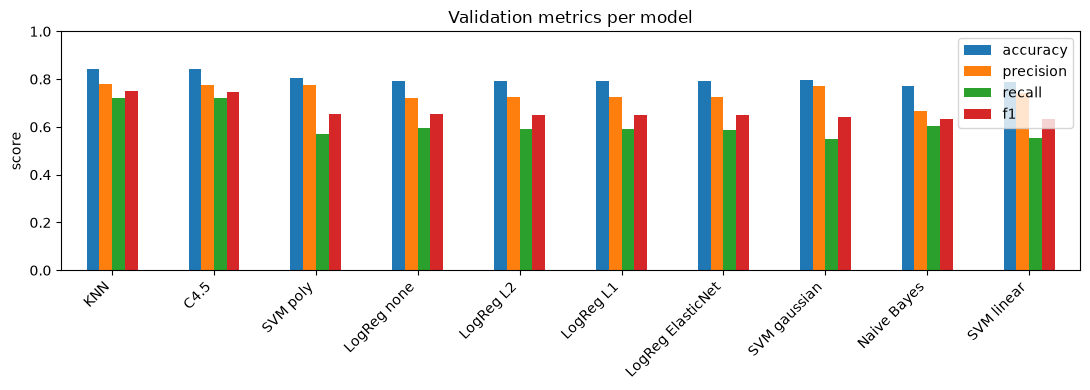

In [48]:
ranking[['accuracy', 'precision', 'recall', 'f1']].plot.bar(figsize=(11, 4))
plt.title('Validation metrics per model')
plt.ylabel('score')
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / 'metrics_per_model.png', dpi=150)
plt.show()

## Improvements (Optional)

Hyperparameter tuning and k-fold cross-validation are not part of this run. Every model uses the settings above.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [49]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.svm import SVC
from sklearn.naive_bayes import CategoricalNB

n_train = len(data['dense'][0])
nb_categories = np.maximum(data['nb'][0].max(axis=0), data['nb'][2].max(axis=0)).astype(int) + 1


def sklearn_counterpart(model):
    if isinstance(model, KNN):
        return KNeighborsClassifier(n_neighbors=model.k, weights=model.weights)
    if isinstance(model, C45DecisionTree):
        return DecisionTreeClassifier(criterion='entropy', max_depth=model.max_depth,
                                      ccp_alpha=model.ccp_alpha, random_state=CFG.SEED)
    if isinstance(model, LogisticRegression):
        l1_ratio = {None: 0, 'l2': 0, 'l1': 1, 'elasticnet': model.l1_ratio}[model.penalty]
        C = np.inf if model.penalty is None else 1 / (model.alpha * n_train)
        return SkLogReg(C=C, l1_ratio=l1_ratio, solver='saga', max_iter=2000, random_state=CFG.SEED)
    if isinstance(model, SVM):
        return SVC(C=model.C, kernel=model.kernel, degree=model.degree, gamma=model.gamma, coef0=model.coef0)
    return CategoricalNB(alpha=model.laplace, min_categories=nb_categories)


sk_results = {}
for name, model in all_models.items():
    X_train, y_train, X_val, y_val = data[variants[name]]
    sk = sklearn_counterpart(model)
    if isinstance(model, SVM):
        X_train, y_train = model._subsample(X_train, y_train, np.random.default_rng(model.seed))
    if isinstance(model, NaiveBayes):
        X_train, X_val = X_train.astype(int), X_val.astype(int)
    sk.fit(X_train, y_train)
    if isinstance(model, NaiveBayes) and model.threshold is not None:
        pred = (sk.predict_proba(X_val)[:, 1] >= model.threshold).astype(int)
    else:
        pred = sk.predict(X_val)
    sk_results[name] = metrics.report(y_val, pred)

comparison = pd.concat(
    {'scratch': pd.DataFrame(results).T.reindex(list(sk_results)), 'sklearn': pd.DataFrame(sk_results).T},
    axis=1,
)
comparison.round(3)

/home/putra/.local/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


scratch                                   sklearn  \
                  accuracy precision recall     f1 macro_f1 accuracy   
KNN                  0.842     0.779  0.722  0.750    0.817    0.842   
C4.5                 0.840     0.775  0.722  0.748    0.816    0.849   
LogReg none          0.792     0.721  0.597  0.653    0.753    0.794   
LogReg L1            0.792     0.723  0.593  0.651    0.752    0.793   
LogReg L2            0.793     0.724  0.592  0.652    0.752    0.793   
LogReg ElasticNet    0.792     0.725  0.588  0.649    0.751    0.793   
SVM linear           0.790     0.741  0.552  0.633    0.743    0.790   
SVM poly             0.804     0.773  0.569  0.655    0.759    0.804   
SVM gaussian         0.798     0.769  0.548  0.640    0.750    0.798   
Naive Bayes          0.772     0.668  0.602  0.633    0.734    0.772   

                                                    
                  precision recall     f1 macro_f1  
KNN                   0.779  0.722  0.750    0.817  
C4.5                  0.794  0.731  0.761    0.826  
LogReg none           0.727  0.593  0.653    0.753  
LogReg L1             0.726  0.589  0.650    0.751  
LogReg L2             0.726  0.590  0.651    0.752  
LogReg ElasticNet     0.727  0.589  0.650    0.752  
SVM linear            0.740  0.555  0.634    0.744  
SVM poly              0.774  0.568  0.655    0.759  
SVM gaussian          0.770  0.549  0.641    0.750  
Naive Bayes           0.668  0.602  0.633    0.734

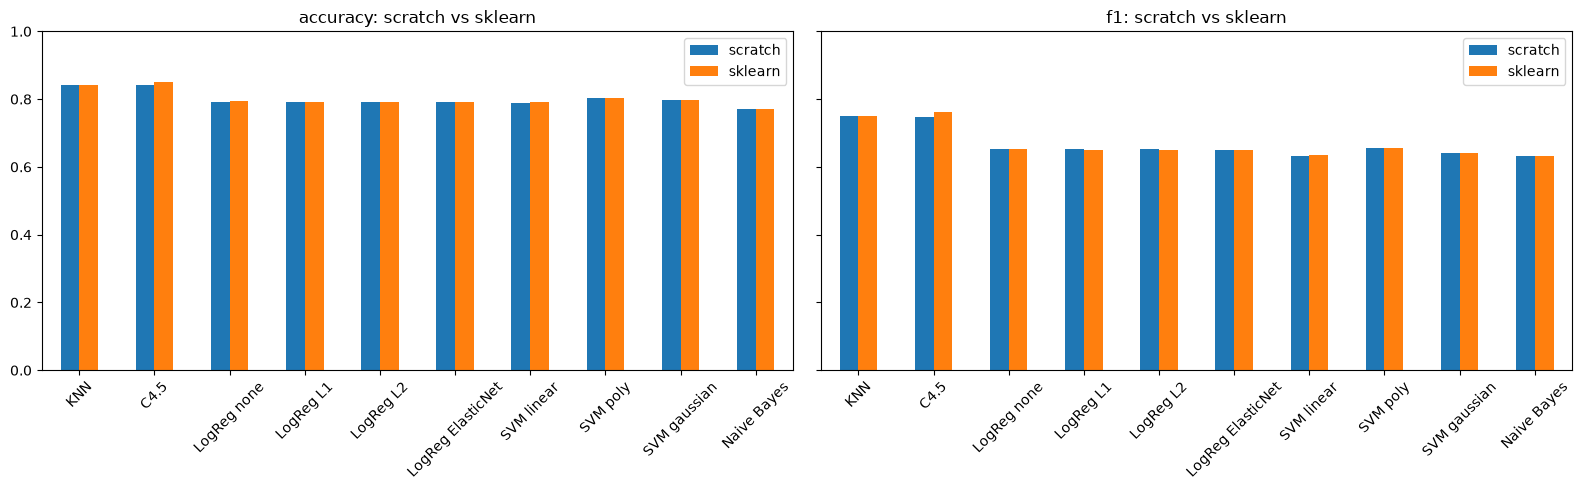

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, metric in zip(axes, ['accuracy', 'f1']):
    comparison.xs(metric, axis=1, level=1).plot.bar(ax=ax)
    ax.set_title(f'{metric}: scratch vs sklearn')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / 'scratch_vs_sklearn.png', dpi=150)
plt.show()

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [51]:
for name, model in all_models.items():
    X_val = data[variants[name]][2]
    path = CFG.MODEL_DIR / re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')
    model.save(path)
    loaded = type(model).load(path)
    assert np.array_equal(model.predict(X_val), loaded.predict(X_val)), name
print(f'{len(all_models)} models saved and reloaded identically')

10 models saved and reloaded identically


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [52]:
encoding = ENCODINGS[variants[BEST_NAME]]
(X_full, X_test_final), y_full, _ = prepare(train_df, [test_df], encoding)

final_model = factories[BEST_NAME]()
final_model.fit(X_full, y_full)

submission = pd.DataFrame({CFG.ID: test_df[CFG.ID], CFG.TARGET: final_model.predict(X_test_final)})
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
submission.head()

,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [53]:
best_pred = all_models[BEST_NAME].predict(data[variants[BEST_NAME]][2])
print(BEST_NAME)
print(metrics.confusion_matrix(y_val, best_pred))

analysis = val_set.assign(wrong=best_pred != val_set[CFG.TARGET].to_numpy(), pred=best_pred)
analysis['lead_time'] = pd.cut(analysis['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
for column in ['booking_channel', 'lead_time', 'special_requests']:
    print(analysis.groupby(column, observed=True)['wrong'].agg(error_rate='mean', rows='size').round(3), '\n')

KNN
[[3313  368]
 [ 498 1296]]
                     error_rate  rows
booking_channel                      
Airline                   0.136    22
Complimentary             0.016    63
Corporate                 0.087   299
Offline Agent             0.075  1642
Online Travel Agent       0.207  3449 

            error_rate  rows
lead_time                   
(-1, 7]          0.097   812
(7, 30]          0.157   962
(30, 90]         0.174  1599
(90, 180]        0.205  1100
(180, 500]       0.097   762 

                  error_rate  rows
special_requests                  
0.0                    0.159  2544
1.0                    0.187  1713
2.0                    0.098   642
3.0                    0.011    88
4.0                    0.000    13 



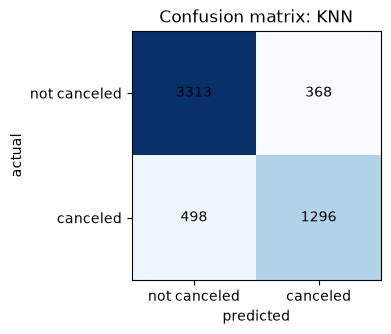

In [54]:
cm = metrics.confusion_matrix(y_val, best_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha='center', va='center')
ax.set_xticks([0, 1], ['not canceled', 'canceled'])
ax.set_yticks([0, 1], ['not canceled', 'canceled'])
ax.set_xlabel('predicted')
ax.set_ylabel('actual')
ax.set_title(f'Confusion matrix: {BEST_NAME}')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / 'confusion_matrix_best.png', dpi=150)
plt.show()